In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy import stats
from scipy.optimize import curve_fit

Import the data:

In [ ]:
data = {
    "Romulus_N2": pd.read_csv("../Data/Romulus_n2.csv"),
    "Romulus_O2": pd.read_csv("../Data/Romulus_o2.csv"),
    "Remus_N2": pd.read_csv("../Data/Remus_n2.csv"),
    "Remus_O2": pd.read_csv("../Data/Remus_o2.csv")
}


The linearised Langmuir equation is $\frac{p}{q}$ = $\frac{1}{{q_s}k}$ + $\frac{1}{q_s}p$, and the linearised Freundlich equation is $ln$ $q$ = $ln$ $k$ + $\frac{1}{m}$ $ln$ $p$.


We must first remove the row containing zeros. Then we transform the data into y and x.

In [ ]:
P_raw = {}
q_raw = {}

x_langmuir = {}
y_langmuir = {}

x_freundlich = {}
y_freundlich = {}

for name, df in data.items():
    df = df[df["P [Pa]"] > 0]
    P = df["P [Pa]"].to_numpy()
    q = df["q [mol kg-1]"].to_numpy()
    P_raw[name] = P
    q_raw[name] = q
    x_langmuir[name] = P
    y_langmuir[name] = P/q
    x_freundlich[name] = np.log(P)
    y_freundlich[name] = np.log(q)

In [ ]:
def langmuir_equation(P,qs,K):
    return qs*K*P / (1+K*P)
def freundlich_equation(P,m,K):
    return K*P**(1/m)
def r_squared(y, y_fit):
    return 1 - np.sum((y - y_fit) ** 2) / np.sum((y - y.mean()) ** 2)


Fit the pure-component data to the linearised versions of the Langmuir and Freundlich isotherms and provide the functional form along with the estimated parameters (with the correct units). 

In [ ]:
def r_squared(y, y_fit):
    return 1 - np.sum((y - y_fit)**2) / np.sum((y - y.mean())**2)

rows = []
for name in x_langmuir:
    results_langmuir = stats.linregress(x_langmuir[name], y_langmuir[name])
    results_freundlich = stats.linregress(x_freundlich[name], y_freundlich[name])

    qs_langmuir = 1 / results_langmuir.slope
    K_langmuir = 1 / (qs_langmuir * results_langmuir.intercept)

    m_freundlich = 1 / results_freundlich.slope
    K_freundlich = np.exp(results_freundlich.intercept)

    # Recover the measured P and q (y_langmuir is P/q, so q = P / y_langmuir)
    P = np.asarray(x_langmuir[name])
    q = P / np.asarray(y_langmuir[name])

    # Uptake predicted by each fitted isotherm
    q_fit_langmuir = qs_langmuir * K_langmuir * P / (1 + K_langmuir * P)
    q_fit_freundlich = K_freundlich * P ** (1 / m_freundlich)

    rows.append({
        "data_set": name,
        "slope_langmuir": results_langmuir.slope,
        "intercept_langmuir": results_langmuir.intercept,
        "R2_langmuir_lin": results_langmuir.rvalue**2,         # your original R2 (on P/q)
        "R2_langmuir": r_squared(q, q_fit_langmuir),           # R2 on q
        "qs_langmuir": qs_langmuir,
        "K_langmuir": K_langmuir,
        "slope_freundlich": results_freundlich.slope,
        "intercept_freundlich": results_freundlich.intercept,
        "R2_freundlich_lin": results_freundlich.rvalue**2,     # your original R2 (on ln q)
        "R2_freundlich": r_squared(q, q_fit_freundlich),       # R2 on q
        "m_freundlich": m_freundlich,
        "K_freundlich": K_freundlich,
    })

results = pd.DataFrame(rows)
pd.set_option("display.float_format", "{:.4e}".format)
display(results)

calculate the standard error propogation of the slope and intercept errors ont the parameter voalues attained. Langmuir, from $q_s = 1/s$ and $K = s/c$:

$$\sigma_{q_s} = \frac{\sigma_s}{s^2}$$

$$\sigma_K = K\sqrt{\left(\frac{\sigma_s}{s}\right)^2 + \left(\frac{\sigma_c}{c}\right)^2 - \frac{2\,\mathrm{cov}(s,c)}{s\,c}}$$

Freundlich, from $m = 1/s$ and $K = e^{c}$:

$$\sigma_m = \frac{\sigma_s}{s^2}$$

$$\sigma_K = K\,\sigma_c$$

where $s$ is the slope, $c$ is the intercept, and $\sigma = \sqrt{\mathrm{variance}}$.

Then append these standard error values to the table above.

**FAlSE WE WILL USE LANGMUIR**

In [ ]:
se_rows = []
for name in x_langmuir:
    # --- Langmuir: fit with polyfit to get the covariance matrix ---
    (s, c), cov = np.polyfit(x_langmuir[name], y_langmuir[name], 1, cov=True)
    sigma_s, sigma_c = np.sqrt(cov[0, 0]), np.sqrt(cov[1, 1])
    cov_sc = cov[0, 1]

    qs = 1 / s
    K = s / c
    se_qs_L = sigma_s / s**2
    se_K_L = abs(K) * np.sqrt((sigma_s / s)**2 + (sigma_c / c)**2 - 2 * cov_sc / (s * c))

    # --- Freundlich ---
    (s_f, c_f), cov_f = np.polyfit(x_freundlich[name], y_freundlich[name], 1, cov=True)
    sigma_s_f, sigma_c_f = np.sqrt(cov_f[0, 0]), np.sqrt(cov_f[1, 1])

    K_f = np.exp(c_f)
    se_m_F = sigma_s_f / s_f**2
    se_K_F = K_f * sigma_c_f

    se_rows.append({
        "se_qs_langmuir": se_qs_L,
        "se_K_langmuir": se_K_L,
        "se_m_freundlich": se_m_F,
        "se_K_freundlich": se_K_F,
    })

se_df = pd.DataFrame(se_rows)
results_with_se = pd.concat([results, se_df], axis=1)
display(results_with_se)

This is sufficient evidence to fit the data to isotherms.

Units: $P$ in Pa, $q$ in mol kg$^{-1}$. Parameters come from the linearised fits; $\pm$ values are one standard error. On the uptake $q$, the Langmuir model fits all four data sets with $R^2 \geq 0.998$, so it is used for both gases.

### Pure-component Langmuir model (N$_2$ and O$_2$)

$$q = \frac{q_s K P}{1 + K P}$$

**Romulus N$_2$:** $q_s = 2.40 \pm 0.04$ mol kg$^{-1}$, $K = (5.19 \pm 0.21)\times10^{-6}$ Pa$^{-1}$

$$q = \frac{1.25\times10^{-5}\,P}{1 + 5.19\times10^{-6}\,P}$$

**Romulus O$_2$:** $q_s = 3.0 \pm 0.4$ mol kg$^{-1}$, $K = (5.8 \pm 0.9)\times10^{-7}$ Pa$^{-1}$

$$q = \frac{1.77\times10^{-6}\,P}{1 + 5.84\times10^{-7}\,P}$$

**Remus N$_2$:** $q_s = 2.78 \pm 0.03$ mol kg$^{-1}$, $K = (1.010 \pm 0.017)\times10^{-6}$ Pa$^{-1}$

$$q = \frac{2.81\times10^{-6}\,P}{1 + 1.01\times10^{-6}\,P}$$

**Remus O$_2$:** $q_s = 4.1 \pm 0.4$ mol kg$^{-1}$, $K = (2.6 \pm 0.3)\times10^{-7}$ Pa$^{-1}$

$$q = \frac{1.09\times10^{-6}\,P}{1 + 2.64\times10^{-7}\,P}$$

### Multicomponent (extended Langmuir) model

In the column, N$_2$ and O$_2$ compete for the same sites, so the equilibrium uptake of gas $i$ at partial pressures $p_i = P\,y_i$ is

$$q_i^{*} = \frac{q_{s,i}\,K_i\,p_i}{1 + K_{N_2}\,p_{N_2} + K_{O_2}\,p_{O_2}}$$

using the pure-component $q_s$ and $K$ above.

### Predicted pure-component uptake at 1 bar

| | N$_2$ | O$_2$ | N$_2$/O$_2$ |
|---|---|---|---|
| Romulus | 0.82 mol/kg | 0.167 mol/kg | 4.9 |
| Remus | 0.255 mol/kg | 0.106 mol/kg | 2.4 |

*Valid only within the measured pressure range. The O$_2$ data are far from saturation, so $q_s$ and $K$ for O$_2$ are uncertain individually (10 to 14 %); only their product $q_s K$ is well determined. The extended Langmuir model is an approximation when the $q_s$ values differ, and there is no mixture data to validate it.*

## Adsorption isotherms: uptake vs pressure

Experimental points are shown with the fitted isotherm for each gas: Langmuir for N$_2$ and Freundlich for O$_2$. Curves are drawn only over the measured pressure range, since neither model should be extrapolated beyond it.

In [ ]:
# --- Langmuir parameters for each data set, taken from your results table ---
params = results.set_index("data_set")
lang = {name: (params.loc[name, "qs_langmuir"], params.loc[name, "K_langmuir"])
        for name in params.index}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, material in zip(axes, ["Romulus", "Remus"]):
    for gas, colour in [("N2", "tab:blue"), ("O2", "tab:red")]:
        name = f"{material}_{gas}"
        P_fit = np.linspace(P_raw[name].min(), P_raw[name].max(), 300)
        ax.scatter(P_raw[name], q_raw[name], color=colour, s=18, label=f"{gas} data")
        ax.plot(P_fit, langmuir_equation(P_fit, *lang[name]), color=colour, label=f"{gas} Langmuir")
    ax.set_title(material)
    ax.set_xlabel("P [Pa]")
    ax.legend()
axes[0].set_ylabel("q [mol kg$^{-1}$]")
plt.tight_layout()
plt.show()

# --- Uptake at 1 bar and selectivity (pure-component Langmuir) ---
rows = []
for material in ["Romulus", "Remus"]:
    qs_N2, K_N2 = lang[f"{material}_N2"]
    qs_O2, K_O2 = lang[f"{material}_O2"]
    q_N2 = langmuir_equation(1e5, qs_N2, K_N2)
    q_O2 = langmuir_equation(1e5, qs_O2, K_O2)
    rows.append({"adsorbent": material,
                 "q_N2 at 1 bar [mol/kg]": q_N2,
                 "q_O2 at 1 bar [mol/kg]": q_O2,
                 "S at 1 bar": q_N2 / q_O2,
                 "S at 5 bar": langmuir_equation(5e5, qs_N2, K_N2) / langmuir_equation(5e5, qs_O2, K_O2),
                 "S at P -> 0 (Henry)": (qs_N2 * K_N2) / (qs_O2 * K_O2)})
pd.DataFrame(rows).set_index("adsorbent")

## Selectivity

**Ideal selectivity.** For pure-component isotherms the ideal selectivity is the ratio of the uptakes at the same pressure:

$$S_{N_2/O_2}(P) = \frac{q_{N_2}(P)}{q_{O_2}(P)} = \frac{q_{s,N_2}K_{N_2}}{q_{s,O_2}K_{O_2}}\cdot\frac{1 + K_{O_2}P}{1 + K_{N_2}P}$$

**Henry's-law selectivity.** With Langmuir for both gases, a Henry's-law limit now exists, so the low-pressure selectivity is the ratio of the initial slopes:

$$S_0 = \frac{q_{s,N_2}K_{N_2}}{q_{s,O_2}K_{O_2}}$$

This gives $S_0 \approx 7.1$ for Romulus and $\approx 2.6$ for Remus.

**Pressure dependence.** $S$ falls with pressure because $K_{N_2} > K_{O_2}$, so N$_2$ saturates first. At 1 bar $S \approx 4.9$ (Romulus) and $2.4$ (Remus), and at 5 bar $S \approx 2.5$ and $1.9$.

**Competitive (mixture) selectivity.** In the extended Langmuir model both gases share one denominator, so the mixture selectivity $\dfrac{q_{N_2}/y_{N_2}}{q_{O_2}/y_{O_2}}$ equals $S_0$ at any pressure and composition. The ideal selectivity at finite pressure is lower than $S_0$ only because of the different saturation behaviour of the pure-component curves.

In [ ]:
# Ideal selectivity N2/O2 over the pressure range covered by both gases for each material
fig, ax = plt.subplots(figsize=(6, 4))
for material, colour in [("Romulus", "tab:green"), ("Remus", "tab:purple")]:
    n2, o2 = f"{material}_N2", f"{material}_O2"
    P_lo = max(P_raw[n2].min(), P_raw[o2].min())
    P_hi = min(P_raw[n2].max(), P_raw[o2].max())
    P_grid = np.linspace(P_lo, P_hi, 300)

    # Pure-component Langmuir uptakes at the same pressure
    S = langmuir_equation(P_grid, *lang[n2]) / langmuir_equation(P_grid, *lang[o2])

    # Henry's-law limit (P -> 0): ratio of the initial slopes qs*K
    S_henry = (lang[n2][0] * lang[n2][1]) / (lang[o2][0] * lang[o2][1])

    ax.plot(P_grid, S, color=colour, label=material)
    ax.axhline(S_henry, color=colour, linestyle=":", linewidth=1)
    print(f"{material}: S = {S[0]:.2f} at {P_lo:.3g} Pa, {S[-1]:.2f} at {P_hi:.3g} Pa, Henry limit S0 = {S_henry:.2f}")

ax.set_xlabel("P [Pa]")
ax.set_ylabel("Ideal selectivity $q_{N_2}/q_{O_2}$")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
results = results.set_index("data_set")
results = results.sort_index()
results


**Component mass balance**
$$\frac{\partial y_i}{\partial t} = D_L \frac{\partial^2 y_i}{\partial z^2} - \frac{\partial (y_i v)}{\partial z} - \frac{R T \rho_s (1-\varepsilon)}{P\,\varepsilon}\frac{\partial q_i}{\partial t}, \qquad \sum_i y_i = 1 \tag{1}$$

**Axial dispersion**
$$D_L = 0.7 D_m + v_{in} r_p \tag{2}$$

**Boundary conditions**
$$z = 0: \quad y_i(z=0) = y_{i,feed} + \frac{D_L}{v}\left.\frac{\partial y_i}{\partial z}\right|_{z=0} \tag{3}$$

$$z = L: \quad \left.\frac{\partial y_i}{\partial z}\right|_{z=L} = 0 \tag{4}$$

**Solid phase mass balance (LDF)**
$$\frac{\partial q_i}{\partial t} = k_i\left(q_i^{*} - q_i\right) \tag{5}$$

In [150]:
res = results if results.index.name == "data_set" else results.set_index("data_set")
for name in ["Romulus_N2", "Romulus_O2", "Remus_N2", "Remus_O2"]:
    print(f"{name:11s} qs = {res.loc[name, 'qs_langmuir']:.4g} mol/kg,  K = {res.loc[name, 'K_langmuir']:.4g} 1/Pa")
    


Romulus_N2  qs = 2.401 mol/kg,  K = 5.192e-06 1/Pa
Romulus_O2  qs = 3.023 mol/kg,  K = 5.839e-07 1/Pa
Remus_N2    qs = 2.783 mol/kg,  K = 1.01e-06 1/Pa
Remus_O2    qs = 4.132 mol/kg,  K = 2.641e-07 1/Pa


In [138]:
# ---------------- Column, operating and feed conditions ----------------
# Column dimensions
L = 0.32            # [m] column length
eps = 0.32          # [-] column void fraction
rho_s = 990         # [kg/m^3] particle density of the adsorbents
r_p = 0.001         # [m] particle radius
# Properties and constants
tau = 3             # [-] tortuosity
D_m = 7.481e-5      # [m^2/s] molecular diffusivity
R = 8.314           # [m^3 Pa/mol/K] universal gas constant
# Operating conditions
T = 303             # [K] temperature
P = 100000          # [Pa] pressure
u_in = 4.864e-3     # [m/s] inlet superficial velocity
# Feed: low-oxygen atmosphere (assumed 5 % O2, balance N2)
y_feed_O2 = 0.05
y_feed_N2 = 1 - y_feed_O2

D_p = D_m / tau                          # particle diffusivity
k = 15 * D_p / r_p**2                    # LDF coefficient (plain Glueckauf)
v_in = u_in / eps                        # inlet interstitial velocity
D_L = 0.7 * D_m + v_in * r_p             # eq. (2) axial dispersion
A = R * T * rho_s * (1 - eps) / (P * eps)   # factor in front of dq/dt in eq. (1)

# --Grid --
N = 200                                  # number of cells (600 is too slow for this solver)
dz = L / N
z = (np.arange(N) + 0.5) * dz            # cell-centre positions

# -- Velocoity --
def mixture_q_eq(material, p_N2, p_O2):
    # Extended Langmuir: equilibrium uptakes of N2 and O2 [mol/kg] at the local partial pressures [Pa]
    qs_N2, K_N2 = lang[f"{material}_N2"]
    qs_O2, K_O2 = lang[f"{material}_O2"]
    denominator = 1 + K_N2 * p_N2 + K_O2 * p_O2
    return qs_N2 * K_N2 * p_N2 / denominator, qs_O2 * K_O2 * p_O2 / denominator

def ldf_model(t, qi, qi_star):
    # eq. (5): dq_i/dt = k (q_i* - q_i)
    return k * (qi_star - qi)

def gas_speed(dq_sum_dt):
    # dv/dz from the sum of eq. (1) over both gases (sum y_i = 1); dq_sum_dt = dq_N2/dt + dq_O2/dt
    return -A * dq_sum_dt

# -- Component mass balance --
def column_model(t, state, material):
    # state = [y_N2 | y_O2 | q_N2 | q_O2], each of length N
    y_N2, y_O2 = state[0:N], state[N:2*N]
    q_N2, q_O2 = state[2*N:3*N], state[3*N:4*N]

    # equilibrium loadings from the multicomponent isotherm at the local partial pressures
    qstar_N2, qstar_O2 = mixture_q_eq(material, P * y_N2, P * y_O2)

    # eq. (5): solid-phase uptake rates
    dq_N2 = ldf_model(t, q_N2, qstar_N2)
    dq_O2 = ldf_model(t, q_O2, qstar_O2)

    v = np.empty(N + 1)
    v[0] = v_in
    v[1:] = v_in + np.cumsum(gas_speed(dq_N2 + dq_O2)) * dz

    def dy_dt(y, y_feed, dq):
        # eq. (1): dy/dt = -dF/dz - A dq/dt, with face flux F = y v - D_L dy/dz
        F = np.empty(N + 1)
        F[0] = v_in * y_feed                                                    # inlet (eq. 3)
        F[1:N] = v[1:N] * 0.5 * (y[:-1] + y[1:]) - D_L * (y[1:] - y[:-1]) / dz  # interior faces
        F[N] = v[N] * y[-1]                                                     # outlet, dy/dz = 0 (eq. 4)
        return -(F[1:] - F[:-1]) / dz - A * dq

    return np.concatenate([dy_dt(y_N2, y_feed_N2, dq_N2),
                           dy_dt(y_O2, y_feed_O2, dq_O2),
                           dq_N2, dq_O2])

# -- Initially sat with O2 --
def initial_state(material):
    # column full of pure O2 in the gas phase; solid in equilibrium with pure O2 at P and holding no N2
    y_N2 = np.zeros(N)
    y_O2 = np.ones(N)
    q_N2 = np.zeros(N)
    q_O2 = np.full(N, mixture_q_eq(material, 0.0, P)[1])
    return np.concatenate([y_N2, y_O2, q_N2, q_O2])

# -- Solve --
t_end = 1500                            
t_eval = np.linspace(0, t_end, 301)

sols = {}
for material in ["Romulus", "Remus"]:
    sols[material] = solve_ivp(column_model, (0, t_end), initial_state(material), method="LSODA", t_eval=t_eval, args=(material,), rtol=1e-6, atol=1e-9)
    print(f"{material}: {sols[material].message}")

Romulus: The solver successfully reached the end of the integration interval.
Remus: The solver successfully reached the end of the integration interval.


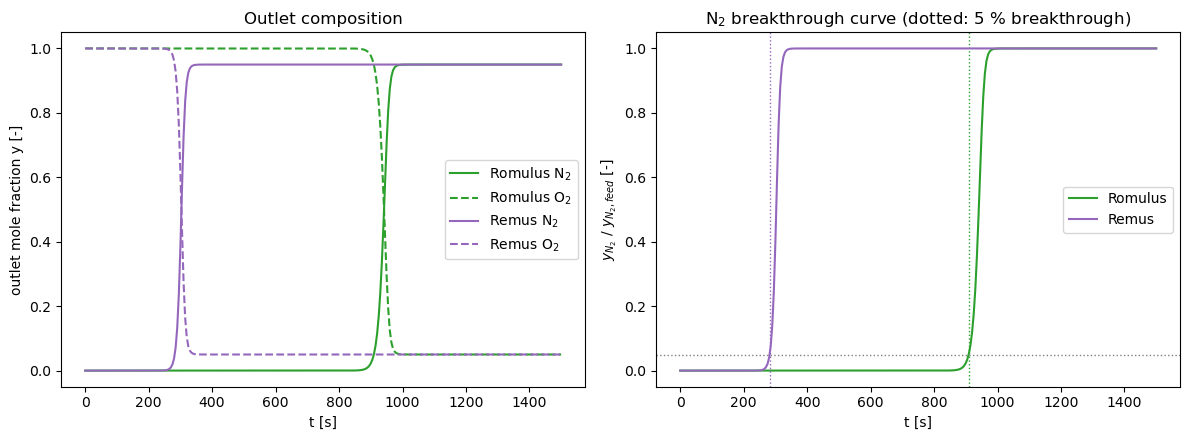

,t at 5% of feed N2 [s],t at 50% of feed N2 [s],final y_N2 / feed,max |sum y - 1| at outlet
adsorbent,,,,
Romulus,9.0884e+02,9.4078e+02,1.0000e+00,3.4891e-11
Remus,2.8146e+02,3.0255e+02,1.0000e+00,5.2844e-12


In [152]:
colours = {"Romulus": "tab:green", "Remus": "tab:purple"}

# ---------------- Breakthrough times (time for outlet N2 to reach a fraction of its feed value) ----------------
def time_at(sol, fraction):
    y_rel = sol.y[N - 1] / y_feed_N2
    if y_rel.max() < fraction:
        return np.nan
    i = np.argmax(y_rel >= fraction)
    return np.interp(fraction, y_rel[i - 1:i + 1], sol.t[i - 1:i + 1])

# ---------------- Plots ----------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: outlet mole fractions of both gases
for material, sol in sols.items():
    axes[0].plot(sol.t, sol.y[N - 1],     color=colours[material], label=f"{material} N$_2$")
    axes[0].plot(sol.t, sol.y[2 * N - 1], color=colours[material], linestyle="--", label=f"{material} O$_2$")
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("outlet mole fraction y [-]")
axes[0].set_title("Outlet composition")
axes[0].legend()

# Right: normalised N2 breakthrough curve with the 5 % breakthrough time marked
for material, sol in sols.items():
    t_5 = time_at(sol, 0.05)
    axes[1].plot(sol.t, sol.y[N - 1] / y_feed_N2, color=colours[material], label=material)
    axes[1].axvline(t_5, color=colours[material], linestyle=":", linewidth=1)
axes[1].axhline(0.05, color="grey", linestyle=":", linewidth=1)
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("$y_{N_2}$ / $y_{N_2,feed}$ [-]")
axes[1].set_title("N$_2$ breakthrough curve (dotted: 5 % breakthrough)")
axes[1].legend()

plt.tight_layout()
plt.show()

# ---------------- Summary table ----------------
summary = []
for material, sol in sols.items():
    summary.append({"adsorbent": material,
                    "t at 5% of feed N2 [s]": time_at(sol, 0.05),
                    "t at 50% of feed N2 [s]": time_at(sol, 0.50),
                    "final y_N2 / feed": sol.y[N - 1, -1] / y_feed_N2,
                    "max |sum y - 1| at outlet": np.abs(sol.y[N - 1] + sol.y[2 * N - 1] - 1).max()})
pd.DataFrame(summary).set_index("adsorbent")